In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from tokenize import group


df = pd.read_csv('chat_parsed.csv')
df_info = pd.read_csv('group_info.csv')
group_name = df_info['group_name'].iloc[0]
print(group_name)

Drenas Espanholas


In [3]:
df.columns

Index(['timestamp', 'date', 'time', 'sender', 'message', 'media',
       'line_number', 'datetime', 'hour', 'day_of_week', 'month', 'year'],
      dtype='object')

In [4]:
#scrollab
df.head(20)

,timestamp,date,time,sender,message,media,line_number,datetime,hour,day_of_week,month,year
0,2021-09-03 22:41:35,03/09/21,22:41:35,Alex Reis,Alex Reis 🏎 criou este grupo,no,2,2021-09-03 22:41:35,22,Friday,September,2021
1,2022-06-27 16:30:53,27/06/22,16:30:53,Duarte,Ih pois é,no,4,2022-06-27 16:30:53,16,Monday,June,2022
2,2022-06-27 16:31:03,27/06/22,16:31:03,Duarte,Eu sabia que havia algo com Barcelona,no,5,2022-06-27 16:31:03,16,Monday,June,2022
3,2022-06-27 16:37:30,27/06/22,16:37:30,Duarte,imagem não revelada,yes,6,2022-06-27 16:37:30,16,Monday,June,2022
4,2022-06-27 16:41:02,27/06/22,16:41:02,João Dias,a vida lá é q nao,no,7,2022-06-27 16:41:02,16,Monday,June,2022
5,2022-06-27 16:41:23,27/06/22,16:41:23,João Dias,e se cagarmos nos recursos e formos a vilamoura,no,8,2022-06-27 16:41:23,16,Monday,June,2022
6,2022-06-27 16:41:28,27/06/22,16:41:28,João Dias,nessa semana,no,9,2022-06-27 16:41:28,16,Monday,June,2022
7,2022-06-27 18:45:36,27/06/22,18:45:36,Max,Há resoluções dos exs livro de SSM?,no,10,2022-06-27 18:45:36,18,Monday,June,2022
8,2022-06-27 19:39:09,27/06/22,19:39:09,João Dias,ele aconselha exs e dá a solucao desses,no,11,2022-06-27 19:39:09,19,Monday,June,2022
9,2022-06-27 19:39:14,27/06/22,19:39:14,João Dias,ta na seccao de material de estudo,no,12,2022-06-27 19:39:14,19,Monday,June,2022


In [5]:
df['sender'].unique()

array(['Alex Reis', 'Duarte', 'João Dias', 'Max', 'Zézão', 'Kiko Vieira',
       'Ângelo'], dtype=object)

## 0. Feature Engineering

In [6]:
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df['year'] = df['timestamp'].dt.year
df['hour'] = df['timestamp'].dt.hour
# ensure timestamp column is in datetime format
#coerce: Converts invalid values to NaT and continues
#raise: Raises an error for invalid values
#ignore: Ignores invalid values
df['day'] = df['timestamp'].dt.day_name()
df['accumulated_messages'] = df.groupby('sender')['message'].cumcount() + 1


In [7]:
df.head(5)

,timestamp,date,time,sender,message,media,line_number,datetime,hour,day_of_week,month,year,day,accumulated_messages
0,2021-09-03 22:41:35,03/09/21,22:41:35,Alex Reis,Alex Reis 🏎 criou este grupo,no,2,2021-09-03 22:41:35,22,Friday,September,2021,Friday,1
1,2022-06-27 16:30:53,27/06/22,16:30:53,Duarte,Ih pois é,no,4,2022-06-27 16:30:53,16,Monday,June,2022,Monday,1
2,2022-06-27 16:31:03,27/06/22,16:31:03,Duarte,Eu sabia que havia algo com Barcelona,no,5,2022-06-27 16:31:03,16,Monday,June,2022,Monday,2
3,2022-06-27 16:37:30,27/06/22,16:37:30,Duarte,imagem não revelada,yes,6,2022-06-27 16:37:30,16,Monday,June,2022,Monday,3
4,2022-06-27 16:41:02,27/06/22,16:41:02,João Dias,a vida lá é q nao,no,7,2022-06-27 16:41:02,16,Monday,June,2022,Monday,1


## 1.Temporal analysis

     hour       sender  message_count
0       0    Alex Reis            130
1       0       Duarte            101
2       0    João Dias            114
3       0  Kiko Vieira             46
4       0          Max             73
..    ...          ...            ...
135    23       Duarte             95
136    23    João Dias            291
137    23  Kiko Vieira             46
138    23          Max            131
139    23        Zézão            106

[140 rows x 3 columns]


Text(0, 0.5, 'Number of Messages')

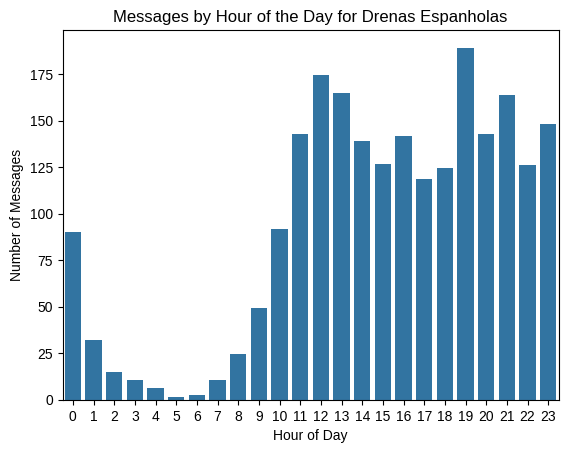

In [8]:
# plot message frequency by hour
#df['hour'].value_counts().sort_index().plot(kind='bar', color='steelblue')
hourly_counts = df.groupby(['hour', 'sender']).size().reset_index(name='message_count')
print(hourly_counts)
sns.barplot(data=hourly_counts, x='hour', y='message_count', errorbar=None)
plt.style.use('seaborn-v0_8')
plt.title(f'Messages by Hour of the Day for {group_name}')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Messages')


### Average activity during a week

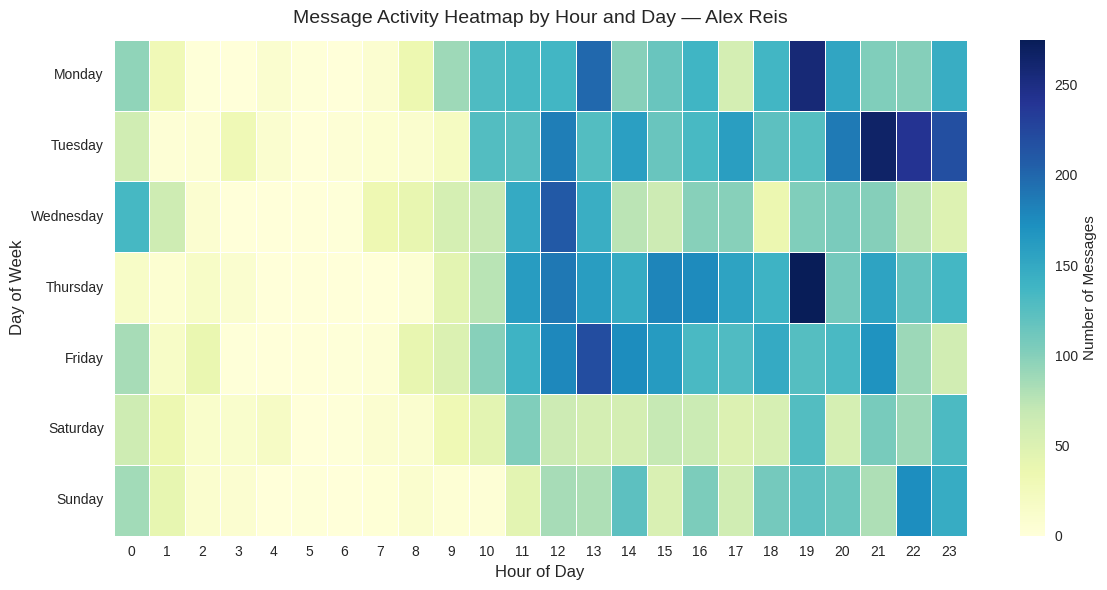

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# group by day and hour
heatmap_data = df.groupby(['day', 'hour']).size().unstack(fill_value=0)

# reorder days for better readability
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(days_order)

# plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', 
    linewidths=0.5, linecolor='white', 
    cbar_kws={'label': 'Number of Messages'}
)
plt.title(f'Message Activity Heatmap by Hour and Day — {df["sender"].iloc[0]}', fontsize=14, pad=12)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Participation Analysis

### Typical content of message by user

/tmp/ipykernel_556636/2576184287.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  message_count = df.groupby(['sender', 'media', pd.Grouper(key='timestamp', freq='M')]).size().reset_index(name='message_count')


      sender media  timestamp  message_count
0  Alex Reis    no 2021-09-30              1
1  Alex Reis    no 2022-06-30             45
2  Alex Reis    no 2022-07-31            122
3  Alex Reis    no 2022-08-31             31
4  Alex Reis    no 2022-09-30            200


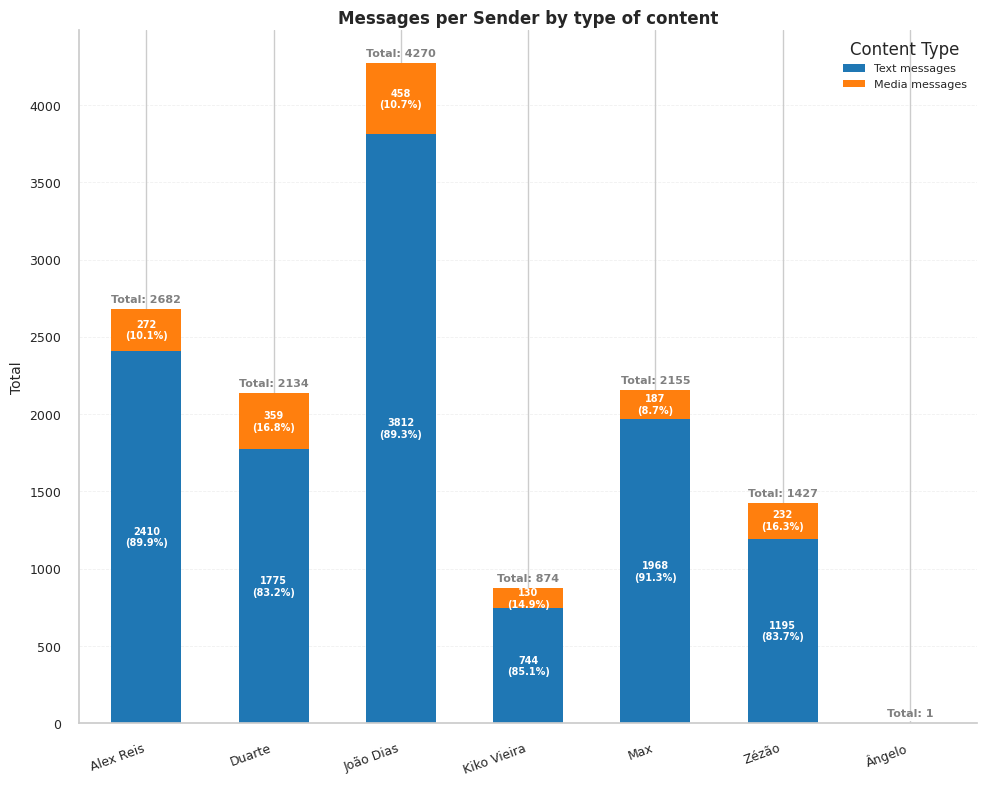

In [10]:
message_count = df.groupby(['sender', 'media', pd.Grouper(key='timestamp', freq='M')]).size().reset_index(name='message_count')
print(message_count.head())
pivot = (
    message_count
    .groupby(['sender', 'media'])['message_count']
    .sum()
    .unstack(fill_value=0)
)

# --- Compact plot style ---
sns.set_theme(style="whitegrid")
colors = ["#1f77b4", "#ff7f0e"]  # blue and orange

fig, ax = plt.subplots(figsize=(10, 8))
pivot.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=colors,
    width=0.55,
    edgecolor='none'
)

# --- Compact aesthetics ---
ax.set_title("Messages per Sender by type of content", fontsize=12, fontweight="bold", pad=5)
ax.set_xlabel("")
ax.set_ylabel("Total", fontsize=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=9)
ax.tick_params(axis='y', labelsize=9)

# Minimal grid and borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.3, linewidth=0.6)

# --- Annotate individual values and percentages ---
totals = pivot.sum(axis=1)
for i, (sender, row) in enumerate(pivot.iterrows()):
    total = row.sum()
    
    # Calculate percentages
    no_pct = (row.get('no', 0) / total * 100) if total > 0 else 0
    yes_pct = (row.get('yes', 0) / total * 100) if total > 0 else 0
    
    # Get individual values
    no_count = row.get('no', 0)
    yes_count = row.get('yes', 0)
    
    # Annotate "no" (regular messages) - bottom of stack
    if no_count > 0:
        ax.text(i, no_count/2, f"{int(no_count)}\n({no_pct:.1f}%)", 
                ha='center', va='center', fontsize=7, color='white', fontweight='bold')
    
    # Annotate "yes" (media messages) - top of stack
    if yes_count > 0:
        ax.text(i, no_count + yes_count/2, f"{int(yes_count)}\n({yes_pct:.1f}%)", 
                ha='center', va='center', fontsize=7, color='white', fontweight='bold')
    
    # Annotate total at the top
    ax.text(i, total + 30, f"Total: {int(total)}", ha='center', va='bottom', 
            fontsize=8, color='gray', fontweight='bold')

# --- Legend ---
ax.legend(title="Content Type", fontsize=8, loc='upper right', frameon=False)

# Update legend labels
legend = ax.get_legend()
if legend:
    legend.get_texts()[0].set_text('Text messages')  # Changes 'no' to 'Text messages'
    legend.get_texts()[1].set_text('Media messages')  # Changes 'yes' to 'Media messages'


plt.tight_layout(pad=1)
plt.show()

### Boxplots (Top view of dist.)

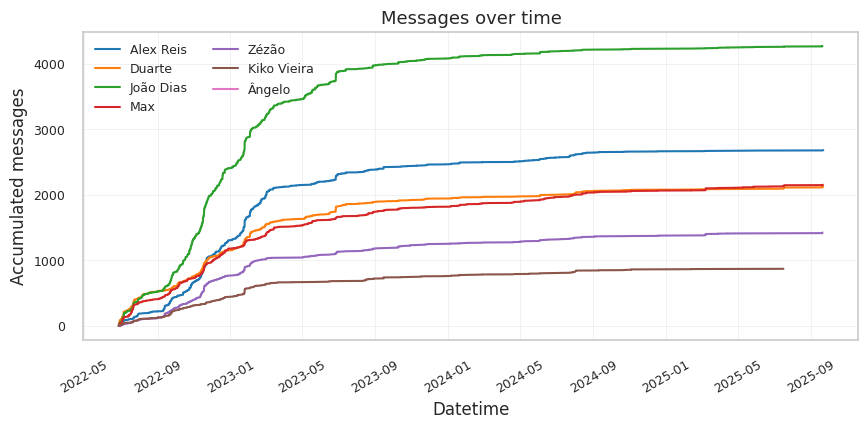

In [11]:
sns.set_palette("tab10")  # or try "tab10", "colorblind", "Dark2"
fig, ax = plt.subplots(figsize=(10, 4))
df['timestamp_'] = pd.to_datetime(df['timestamp'][1:])
sns.lineplot(data=df, x="timestamp_", y="accumulated_messages", hue="sender")
plt.title("Messages over time", fontsize=13)
plt.xlabel("Datetime")
plt.ylabel("Accumulated messages")
# Compact tick formatting
plt.xticks(rotation=30, fontsize=9)
plt.yticks(fontsize=9)
plt.grid(True, alpha=0.3, linewidth=0.6)
#more space between the lines
# Compact legend
plt.legend(
    title=None,
    fontsize=9,
    loc="upper left",
    frameon=False,
    ncol=2  # 2-column legend to save space
)
plt.show()

/tmp/ipykernel_556636/2088974278.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'][1:])


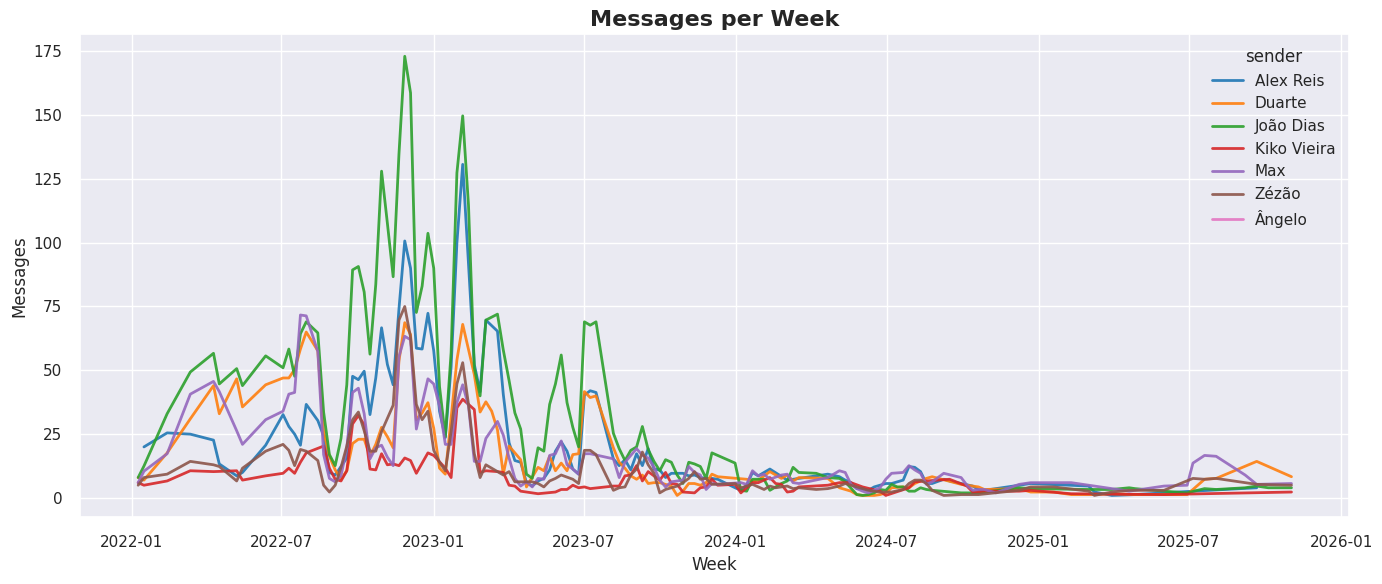

        sender       date  messages_per_week  messages_smooth
264  João Dias 2022-11-20                315       134.666667
274  João Dias 2023-01-29                234       127.333333
27   Alex Reis 2022-11-20                176        74.000000
261  João Dias 2022-10-30                171       128.000000
268  João Dias 2022-12-18                162        83.000000


In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure 'date' is a datetime
df['date'] = pd.to_datetime(df['date'][1:])

# --- Aggregate per sender per week ---
weekly_counts = (
    df.groupby(['sender', pd.Grouper(key='date', freq='W')])
    .size()
    .reset_index(name='messages_per_week')
)

# --- 3-week moving average for smoother trends ---
weekly_counts['messages_smooth'] = (
    weekly_counts.groupby('sender')['messages_per_week']
    .transform(lambda x: x.rolling(3, min_periods=1).mean())
)

# --- Plot ---
plt.style.use("dark_background")
sns.set_theme(style="darkgrid", palette="tab10")

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=weekly_counts,
    x="date",
    y="messages_smooth",
    hue="sender",
    linewidth=2.0,
    alpha=0.9
)

plt.title("Messages per Week", fontsize=16, fontweight='bold')
plt.xlabel("Week")
plt.ylabel("Messages")
plt.tight_layout()
plt.show()

# --- Optional: top 5 busiest weeks ---
print(
    weekly_counts.sort_values(by='messages_per_week', ascending=False)
    .head(5)
)


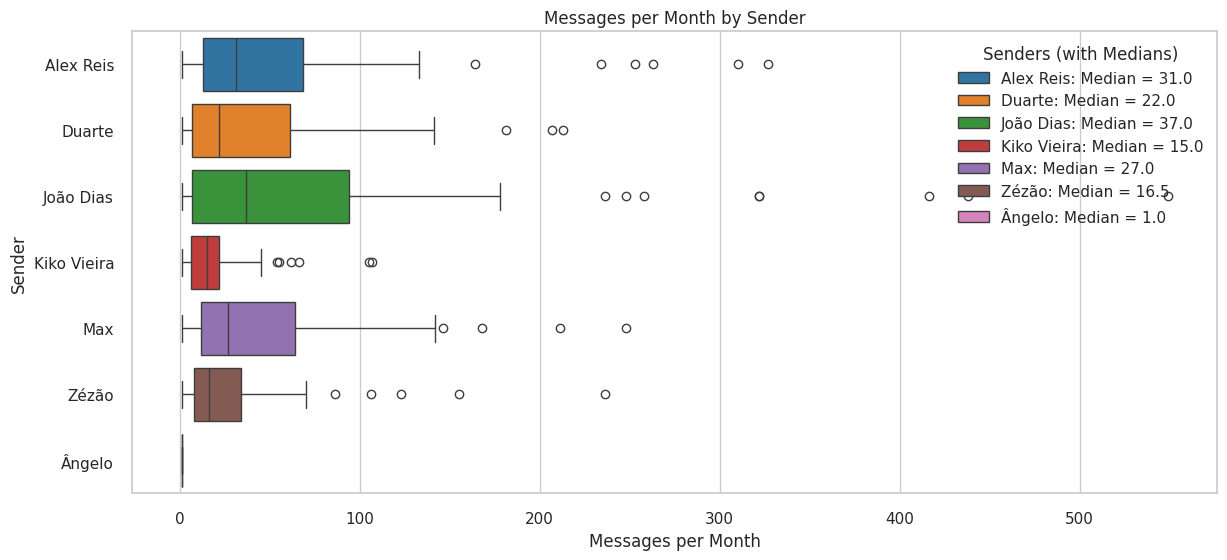

In [13]:
# Ensure 'date' is datetime
df['date'] = pd.to_datetime(df['date'])

# --- Aggregate per sender per month ---
monthly_counts = (
    df.groupby(['sender', pd.Grouper(key='date', freq='ME')])
    .size()
    .reset_index(name='messages_per_month')
)
# --- Plot grouped bar chart ---
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid", palette="tab10")
# Calculate medians for each sender
medians = monthly_counts.groupby('sender')['messages_per_month'].median()
# Create legend with median values


sns.boxplot(data=monthly_counts,
    x="messages_per_month",
    y="sender",
    hue="sender"
)

legend_labels = [f"{sender}: Median = {median:.1f}" for sender, median in medians.items()]
plt.legend(legend_labels, title="Senders (with Medians)", loc='upper right', bbox_to_anchor=(1.0, 1.0))
plt.title("Messages per Month by Sender")
plt.xlabel("Messages per Month")
plt.ylabel("Sender")
plt.show()

### Barplot

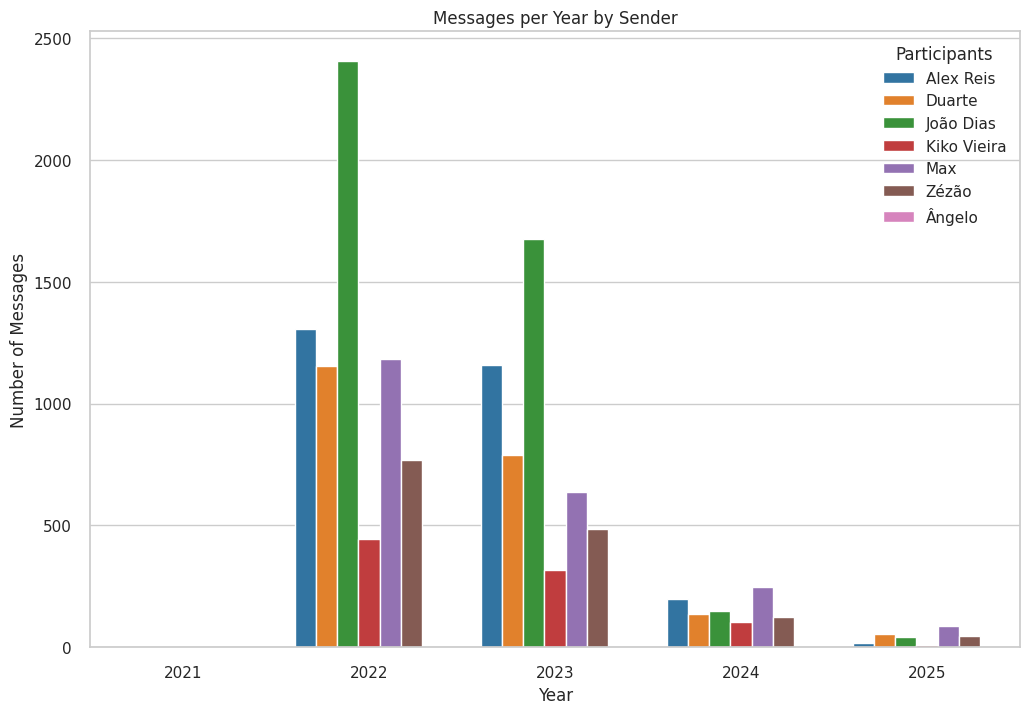

In [14]:
# Create yearly message counts
yearly_messages = df.groupby(['year', 'sender']).size().reset_index(name='message_count')

# Stacked bar chart by year
plt.figure(figsize=(12, 8))
sns.barplot(data=yearly_messages, x='year', y='message_count', hue='sender')
plt.title('Messages per Year by Sender')
plt.xlabel('Year')
plt.ylabel('Number of Messages')
plt.legend(title='Participants')
plt.show()

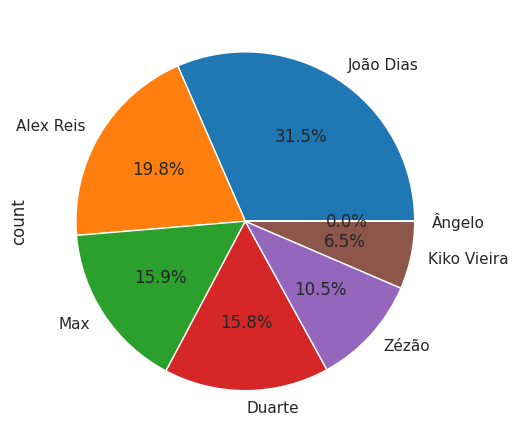

In [15]:
#seaborn pie chart
df['sender'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.show()


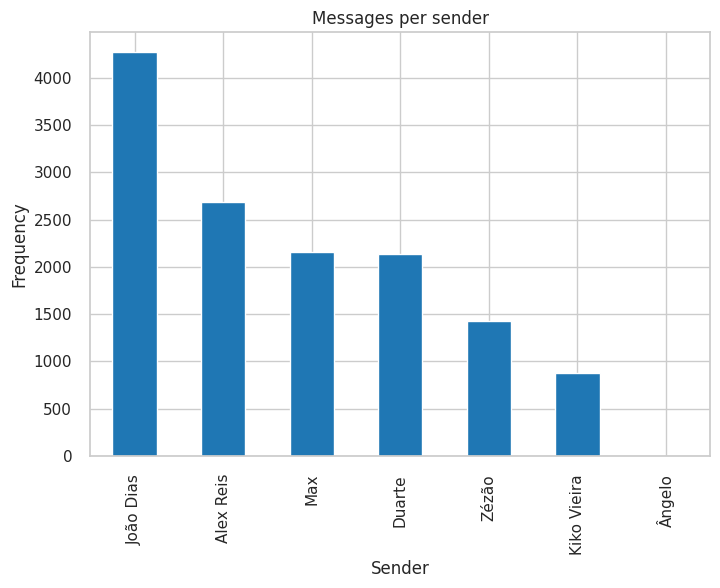

sender
João Dias      31.53
Alex Reis      19.80
Max            15.91
Duarte         15.76
Zézão          10.54
Kiko Vieira     6.45
Ângelo          0.01
Name: proportion, dtype: float64

In [16]:
#percentage of messages per sender
df['sender'].value_counts(normalize=True)

#total messages per sender
df['sender'].value_counts()

#in a bar plot
ax = df['sender'].value_counts().plot(kind='bar') 
ax.set_title('Messages per sender')
ax.set_xlabel('Sender')
ax.set_ylabel('Frequency')
plt.show()

(df['sender'].value_counts(normalize=True) * 100).round(2)


# Sentiment Analysis

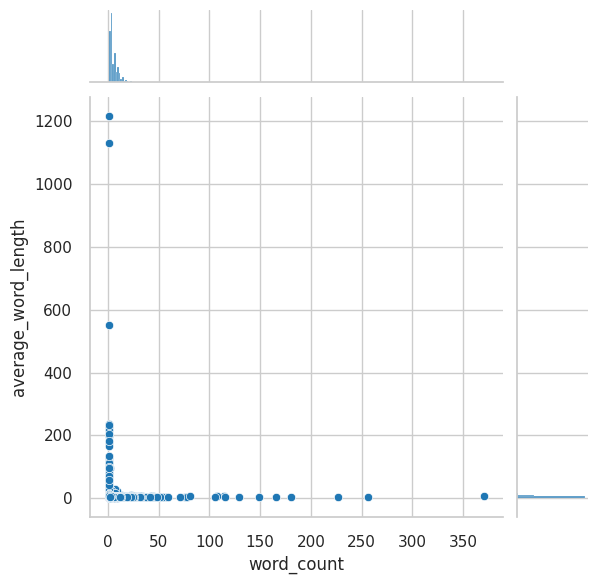

In [23]:
#average menssage lenght
df['message_length'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()
df['average_word_length'] = df['message_length'] / df['word_count']
df.groupby('sender')[['message_length', 'word_count', 'average_word_length']].mean()

sns.jointplot(data=df, x="word_count", y="average_word_length")

   gap_flag    gap_minutes           timestamp
0        no            NaN 2021-09-03 22:41:35
1        no  427309.300000 2022-06-27 16:30:53
2       yes       0.166667 2022-06-27 16:31:03
3        no       6.450000 2022-06-27 16:37:30
4        no       3.533333 2022-06-27 16:41:02
5       yes       0.350000 2022-06-27 16:41:23
6       yes       0.083333 2022-06-27 16:41:28
7        no     124.133333 2022-06-27 18:45:36
8        no      53.550000 2022-06-27 19:39:09
9       yes       0.083333 2022-06-27 19:39:14
10      yes       0.050000 2022-06-27 19:39:17
11       no       3.016667 2022-06-27 19:42:18
12      yes       0.033333 2022-06-27 19:42:20
13       no      36.200000 2022-06-27 20:18:32
14      yes       0.050000 2022-06-27 20:18:35
15       no       2.000000 2022-06-27 20:20:35
16      yes       0.133333 2022-06-27 20:20:43
17      yes       0.033333 2022-06-27 20:20:45
18      yes       1.316667 2022-06-27 20:22:04
19      yes       0.716667 2022-06-27 20:22:47


<Axes: xlabel='year', ylabel='gap_minutes'>

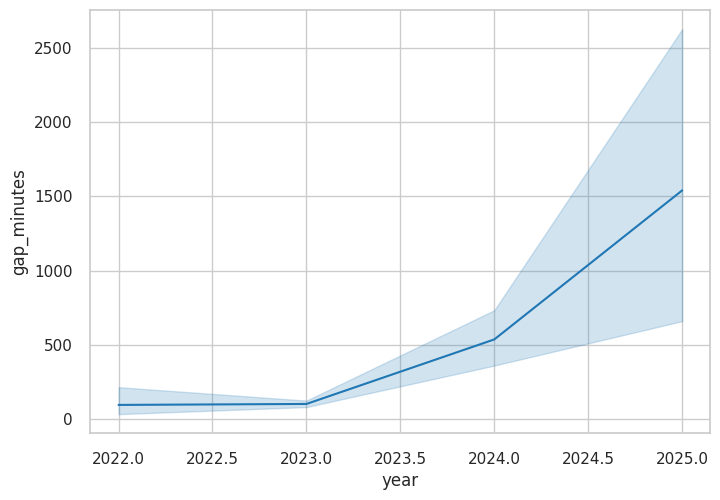

In [18]:
df['time_gap'] = df['timestamp'].diff()
df['gap_seconds'] = df['time_gap'].dt.total_seconds()
df['gap_minutes'] = df['gap_seconds'] / 60

#I want to mark as yes if the gap is less than 5 minutes for N messages in a row
#and have to be more than 10 messages in a row to all get the flag as yes
df['gap_flag'] = df['gap_minutes'].apply(lambda x: 'yes' if x < 2 else 'no')

# Remove first row (NaN) and filter out negative gaps (data issues)
gaps = df['gap_seconds'].dropna()
gaps = gaps[gaps >= 0]  # Remove any negative gaps

print(df[["gap_flag", "gap_minutes", "timestamp"]][0:20])

sns.lineplot(data=df, x="year", y="gap_minutes")


/home/duarte33/Documents/Whatsapp_Chat_Analytics/venv2/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129392 (\N{SMILING FACE WITH SMILING EYES AND THREE HEARTS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


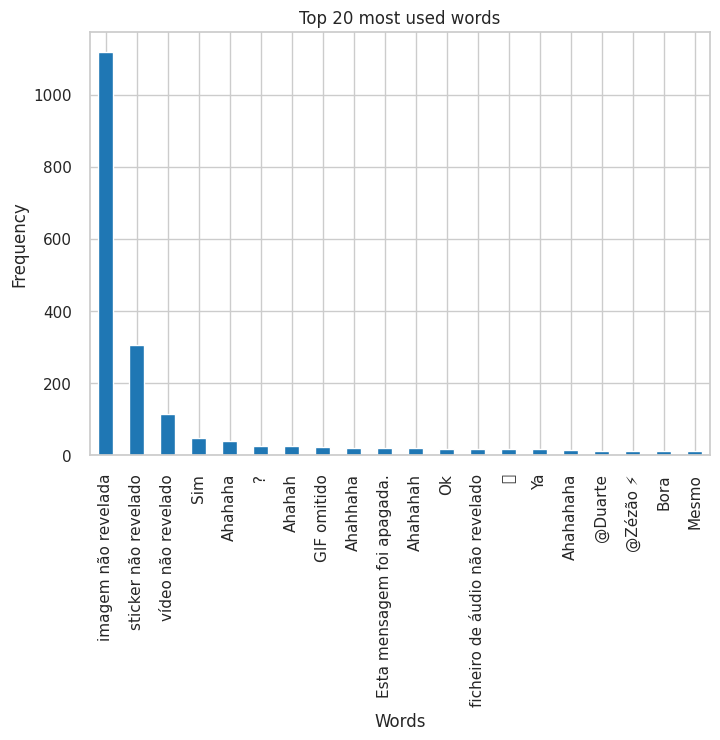

In [19]:
#top most used words
#top most used words
ax = df['message'].value_counts().head(20).plot(kind='bar')
ax.set_title('Top 20 most used words')
ax.set_xlabel('Words')
ax.set_ylabel('Frequency')
plt.show()


In [20]:
import nltk
nltk.download('stopwords')  # Download stopwords data first
from nltk.corpus import stopwords
stopwords = set(stopwords.words('portuguese'))
stopwords.update(['imagem', 'video', 'revelada', 'não', 'Não', 'revelado'])
import re
from collections import Counter

# Get all words
all_words = re.findall(r'\b\w+\b', ' '.join(df['message'].astype(str)).lower())

# Words with only 2 different letters
def has_only_two_unique_letters(word):
    """Check if a word has only 2 unique letters."""
    unique_letters = set(word.lower())
    return len(unique_letters) == 2


# Filter words with only 2 unique letters
for word in all_words:
    word = word.lower()
two_letter_words = [word for word in all_words if has_only_two_unique_letters(word) and len(word) > 2]
print("Words with only 2 different letters:", Counter(two_letter_words).most_common(10))

stopwords.update(two_letter_words)

# Split all sender names and add individual words
all_sender_words = ' '.join(df['sender'].unique()).split()
stopwords.update(all_sender_words)

#except the last one
senders = df['sender'].unique()[1:]
for sender in senders:
    sender_messages = df[df['sender'] == sender]
    all_words = ' '.join(sender_messages['message']).split()
    
    # Calculate word frequencies
    word_freq = {}
    for word in all_words:
        word_freq[word] = word_freq.get(word, 0) + 1
    
    # Sort words by frequency in descending order
    sorted_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
    #filter out words with less than 2 letters
    sorted_words = [word for word in sorted_words if len(word[0]) >= 4]
    #filter out words that are in the stopwords list
    sorted_words = [word for word in sorted_words if word[0] not in stopwords]

    # Get top 5 most distinctive words
    top_words = sorted_words[:5]
    
    # Print results
    print(f"Top 5 most distinctive words for {sender}:")

    # Print top 5 words with their frequencies
    for word, freq in top_words:
        print(f"{word}: {freq}")
    print("\n")



Words with only 2 different letters: [('ele', 231), ('esse', 128), ('ahahah', 89), ('ahahaha', 88), ('ahaha', 86), ('mim', 85), ('dudu', 63), ('okok', 62), ('msm', 48), ('ahahahah', 40)]
Top 5 most distinctive words for Duarte:
vídeo: 44
sticker: 34
fazer: 30
tudo: 27
ciclo: 27


Top 5 most distinctive words for João Dias:
sticker: 126
fazer: 92
acho: 82
agora: 79
porque: 74


Top 5 most distinctive words for Max:
@Zézão: 46
@Duarte: 37
acho: 33
Ahahhaha: 30
fazer: 24


Top 5 most distinctive words for Zézão:
sticker: 31
fazer: 27
acho: 27
vídeo: 24
Isso: 23


Top 5 most distinctive words for Kiko Vieira:
sticker: 58
Ahahaha: 31
Ahaha: 19
acho: 16
ainda: 12


Top 5 most distinctive words for Ângelo:
meninos: 1
anos: 1
aguentei: 1
mais.: 1




[nltk_data] Downloading package stopwords to
[nltk_data]     /home/duarte33/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
